# Milestone 1 - EDA & Baseline Preparation

In [45]:
import os

import librosa 
import matplotlib.pyplot as plt
import pandas as pd

File: bass.wav
Duration: 30.01 seconds
Sampling Rate: 44100 Hz
Total Samples: 1323588


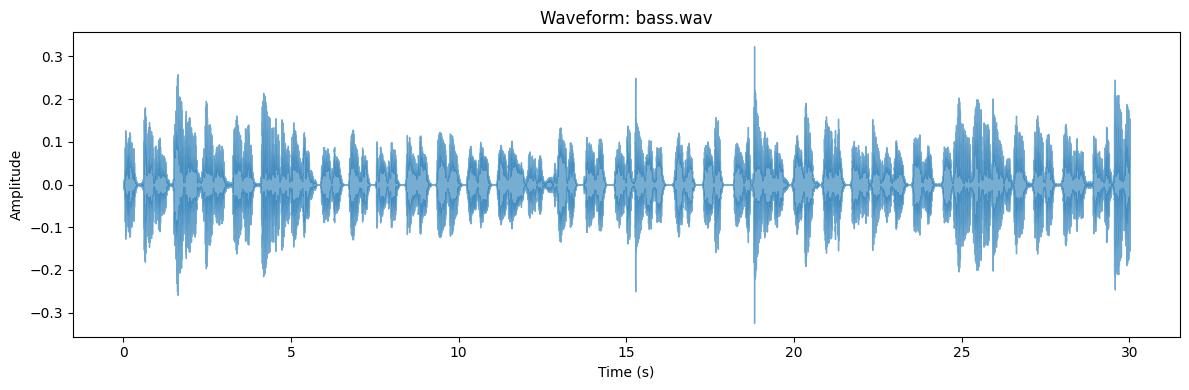

In [46]:
import librosa.display

DATASET_ROOT = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
STEM_NAMES = ["bass.wav", "drums.wav", "other.wav", "vocals.wav"]


def get_song_dirs(dataset_root):
    song_dirs = []
    genres = sorted(os.listdir(dataset_root))
    for genre in genres:
        genre_path = os.path.join(dataset_root, genre)
        if os.path.isdir(genre_path):
            songs = sorted(os.listdir(genre_path))
            for song in songs:
                song_path = os.path.join(genre_path, song)
                if os.path.isdir(song_path):
                    song_dirs.append(song_path)
    return song_dirs


def get_stem_paths(song_dir):
    stem_paths = {}
    for stem in STEM_NAMES:
        stem_paths[stem] = os.path.join(song_dir, stem)
    return stem_paths


def inspect_audio(file_path):
    y, sr = librosa.load(file_path, sr=None)
    duration = librosa.get_duration(y=y, sr=sr)

    print("File:", os.path.basename(file_path))
    print(f"Duration: {duration:.2f} seconds")
    print(f"Sampling Rate: {sr} Hz")
    print("Total Samples:", len(y))

    plt.figure(figsize=(12, 4))
    librosa.display.waveshow(y, sr=sr, alpha=0.6)
    plt.title("Waveform: " + os.path.basename(file_path))
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()


example_path = os.path.join(DATASET_ROOT, "blues", "blues.00001", "bass.wav")
inspect_audio(example_path)

## 1) Dataset Inventory

In [47]:
song_paths = get_song_dirs(DATASET_ROOT)
len(song_paths)

1000

## 2) Data Integrity Check

In [48]:
corrupt_songs = []

for song_path in song_paths:
    stem_paths = get_stem_paths(song_path)
    missing_stems = []
    tiny_stems = []

    for stem, stem_path in stem_paths.items():
        if not os.path.exists(stem_path):
            missing_stems.append(stem)
        elif os.path.getsize(stem_path) < 4096:
            tiny_stems.append(stem)

    if missing_stems or tiny_stems:
        corrupt_songs.append(
            {
                "Song": os.path.basename(song_path),
                "Genre": os.path.basename(os.path.dirname(song_path)),
                "Missing": missing_stems,
                "TinyFiles": tiny_stems,
            }
        )

if len(corrupt_songs) > 0:
    corrupt_df = pd.DataFrame(corrupt_songs)
    corrupt_df.head()
else:
    print("No corrupt files found")

No corrupt files found


## 3) Silence Check

In [49]:
silence_stats = []

for song_path in song_paths:
    vocal_file = os.path.join(song_path, "vocals.wav")
    if not os.path.exists(vocal_file):
        continue

    y, sr = librosa.load(vocal_file, sr=None)
    total_time = librosa.get_duration(y=y, sr=sr)
    non_silent_intervals = librosa.effects.split(y, top_db=20)

    non_silent_time = 0
    for start, end in non_silent_intervals:
        non_silent_time += (end - start) / sr

    silence_time = max(total_time - non_silent_time, 0.0)

    silence_stats.append(
        {
            "Song": os.path.basename(song_path),
            "Genre": os.path.basename(os.path.dirname(song_path)),
            "TotalDurationSec": total_time,
            "SilenceSec": silence_time,
            "SilenceRatio": silence_time / total_time if total_time > 0 else 0.0,
        }
    )

silence_df = pd.DataFrame(silence_stats)
silence_df.head()

,Song,Genre,TotalDurationSec,SilenceSec,SilenceRatio
0,blues.00000,blues,30.013333,10.392472,0.346262
1,blues.00001,blues,30.013333,14.976871,0.499007
2,blues.00002,blues,30.013333,20.040363,0.667715
3,blues.00003,blues,30.013333,20.992381,0.699435
4,blues.00004,blues,30.013333,21.352290,0.711427


## 4) Final Training Table

In [50]:
data = []

for song_path in song_paths:
    stem_paths = get_stem_paths(song_path)
    has_all_files = True
    total_file_size = 0

    for stem_path in stem_paths.values():
        if not os.path.exists(stem_path):
            has_all_files = False
            break
        total_file_size += os.path.getsize(stem_path)

    if has_all_files:
        song_name = os.path.basename(song_path)
        genre = os.path.basename(os.path.dirname(song_path))
        data.append([song_name, total_file_size, genre])

df = pd.DataFrame(data, columns=["Song Name", "Total File Size (Bytes)", "Genre"]).sort_values(["Genre", "Song Name"]).reset_index(drop=True)
df.head()

,Song Name,Total File Size (Bytes),Genre
0,blues.00000,21177720,blues
1,blues.00001,21177720,blues
2,blues.00002,21177720,blues
3,blues.00003,21177720,blues
4,blues.00004,21177720,blues


## 5) Class Distribution

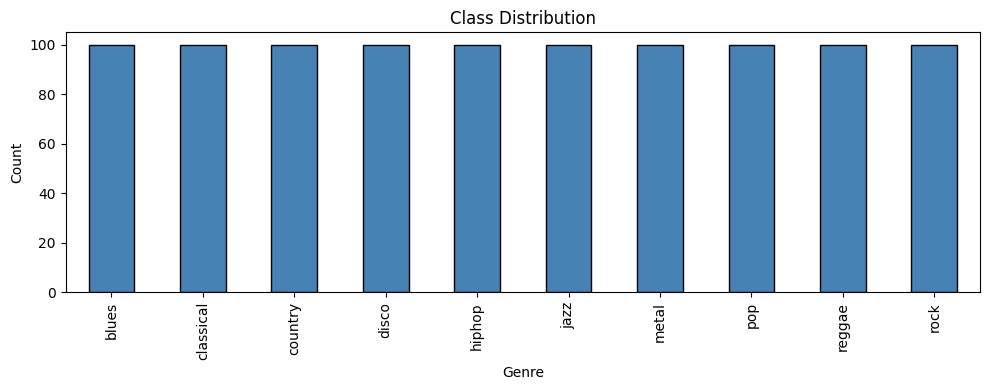

In [51]:
genre_counts = df["Genre"].value_counts().sort_index()
genre_counts

plt.figure(figsize=(10, 4))
genre_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Class Distribution")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 6) Duration Analysis

In [52]:
duration_rows = []

for song_path in song_paths:
    vocal_file = os.path.join(song_path, "vocals.wav")
    if os.path.exists(vocal_file):
        y, sr = librosa.load(vocal_file, sr=None)
        duration_rows.append(
            {
                "Song": os.path.basename(song_path),
                "Genre": os.path.basename(os.path.dirname(song_path)),
                "DurationSec": librosa.get_duration(y=y, sr=sr),
            }
        )

duration_df = pd.DataFrame(duration_rows)
duration_df["DurationSec"].describe()

count    1000.000000
mean       30.024047
std         0.080914
min        29.931973
25%        30.000181
50%        30.013333
75%        30.013333
max        30.648889
Name: DurationSec, dtype: float64

In [53]:
duration_df.groupby("Genre")["DurationSec"].mean().sort_values(ascending=False)

Genre
hiphop       30.089263
jazz         30.032980
classical    30.027941
country      30.023935
rock         30.023156
disco        30.019719
blues        30.013333
reggae       30.005574
metal        30.004390
pop          30.000181
Name: DurationSec, dtype: float64

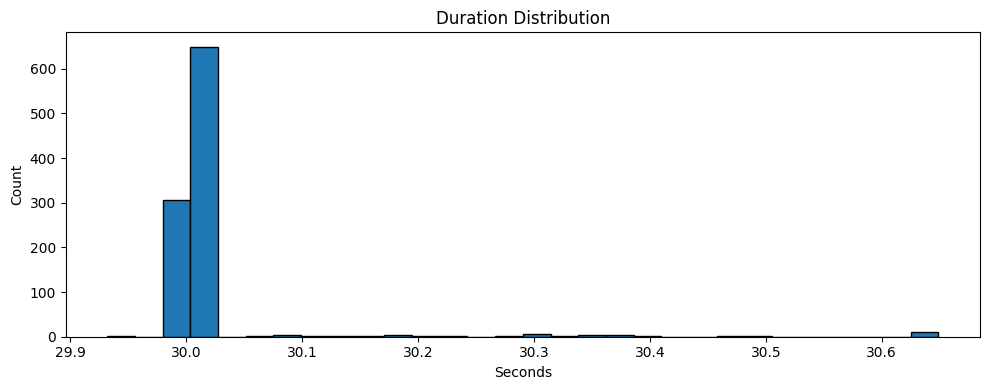

In [54]:
plt.figure(figsize=(10, 4))
plt.hist(duration_df["DurationSec"], bins=30, edgecolor="black")
plt.title("Duration Distribution")
plt.xlabel("Seconds")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 7) ESC-50 Check

In [55]:
esc_meta_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50.csv"

if os.path.exists(esc_meta_path):
    esc_df = pd.read_csv(esc_meta_path)
    print(esc_df[["filename", "fold", "category"]].head())

            filename  fold        category
0   1-100032-A-0.wav     1             dog
1  1-100038-A-14.wav     1  chirping_birds
2  1-100210-A-36.wav     1  vacuum_cleaner
3  1-100210-B-36.wav     1  vacuum_cleaner
4  1-101296-A-19.wav     1    thunderstorm


In [56]:
if os.path.exists(esc_meta_path):
    print(esc_df["category"].value_counts().head(15))

category
dog                40
chirping_birds     40
vacuum_cleaner     40
thunderstorm       40
door_wood_knock    40
can_opening        40
crow               40
clapping           40
fireworks          40
chainsaw           40
airplane           40
mouse_click        40
pouring_water      40
train              40
sheep              40
Name: count, dtype: int64


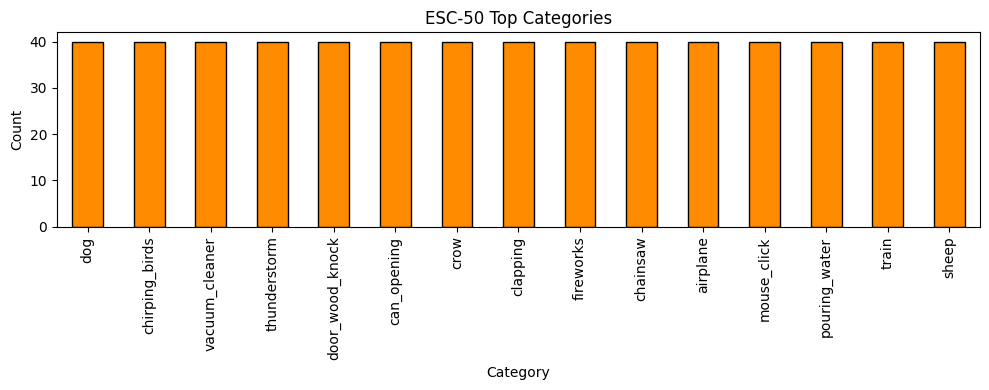

In [57]:
if os.path.exists(esc_meta_path):
    plt.figure(figsize=(10, 4))
    esc_df["category"].value_counts().head(15).plot(kind="bar", color="darkorange", edgecolor="black")
    plt.title("ESC-50 Top Categories")
    plt.xlabel("Category")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 8) Baseline Submission

In [58]:
data = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv")
data.to_csv("submission.csv",index=False)